In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [2]:
%matplotlib inline
sys.path.append("..")
import wavelet_transform.utils.training_data as train
import wavelet_transform.postprocess.plotting as plot

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Set pararmeters for bubble dynamics model

In [3]:
pac = -5E5                                  # the amplitude of the sine wave in Pa
frequency = 5E5                  # insonation frequency (Hz)
no_cycle = 20                               # no. of cycles of the sine wave
sampling_rate = 500E6      # sampling rate to generate the time vector
real_sampling_rate = 50E6
tstep = 1. / sampling_rate
tmax = no_cycle / frequency
time = np.arange(0., tmax, tstep) # time vector for computing the sine wave, in seconds
t_plot = time

R_init = 10E-6                  # initial bubble radius in meters
Rdot_init = 0                   # initial bubble's wall velocity in m/s

r_measure = 50*R_init           # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time 

std_noise = 0.01

wavelet = "db20"
levels = 3
mode = "symmetric"

fft_lim = 10 * frequency  # increase value to view more of the fft plots

### Training data

Run bubble dynamics over a range of frequencies and intensities to generate a larger array of training data.

In [4]:
wpt_df = pd.DataFrame(
        columns=[
            "node",
            "inverse",
            "fft",
            "energy",
            "kurtosis",
            "crest",
            "entropy",
            "skewness",
        ]
    )

i = 0
for frequency in [i * 1E5 for i in range(5, 10)]:
    for pac in [-i * 1E5 for i in range(1, 10)]:
        data = train.generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure)
        if max(data) > 70 or np.isnan(data).any():  # filter out failed dynamics model computations
            continue
        data = (data - np.mean(data))/np.std(data)

        i += 1
        # plt.plot(data)
        # plt.title(f"Frequency: {frequency}, pac: {pac}")
        # plt.show()
        step = int(sampling_rate/real_sampling_rate)
        training_data = train.generate_training_data(
            data[::step], levels, wavelet, mode, min_energy=0
        )
        wpt_df = pd.concat([wpt_df, training_data], ignore_index=True)

print(i)  # print number of signals in training data

45


### Training

Train fuzzy c-means on the generated data

In [5]:
from sklearn.preprocessing import StandardScaler
import skfuzzy as fuzz

# Get data
classifying_metrics = ["energy", "entropy", "kurtosis", "crest"]
data_train = wpt_df[classifying_metrics]

# Standardise data
scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# Parameters for Fuzzy C-means
no_clusters = 3
m = 1.5
error = 1e-6

# Fuzzy C-Means clustering
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    data_train_normalised.T,
    c=no_clusters,
    m=m,
    error=error,
    maxiter=100,
)
print("number of iterations:", p)
# Cluster centres
centers = scaler.inverse_transform(cntr)
print("centers:", centers)
# Membership matrix
membership_matrix = u.T

# Hard cluster assignments
labels = np.argmax(membership_matrix, axis=1)
for i in range(no_clusters):
    print(f"label {i} count:", list(labels).count(i))

# membership_results = pd.DataFrame()
# for i, membership in enumerate(membership_matrix):
#     membership_results.loc[i, "hard assignment"] = labels[i]
#     for j in range(no_clusters):
#         membership_results.loc[i, f"membership {j}"] = membership[j]

# membership_results.head()

number of iterations: 54
centers: [[ 0.29729034  2.36246087 54.02695395  7.28445604]
 [ 0.12595625  4.0477655  11.61828512  2.01487776]
 [ 6.03895211  4.96468764  3.79928689 -1.85749935]]
label 0 count: 171
label 1 count: 145
label 2 count: 44


Plotting clustering results

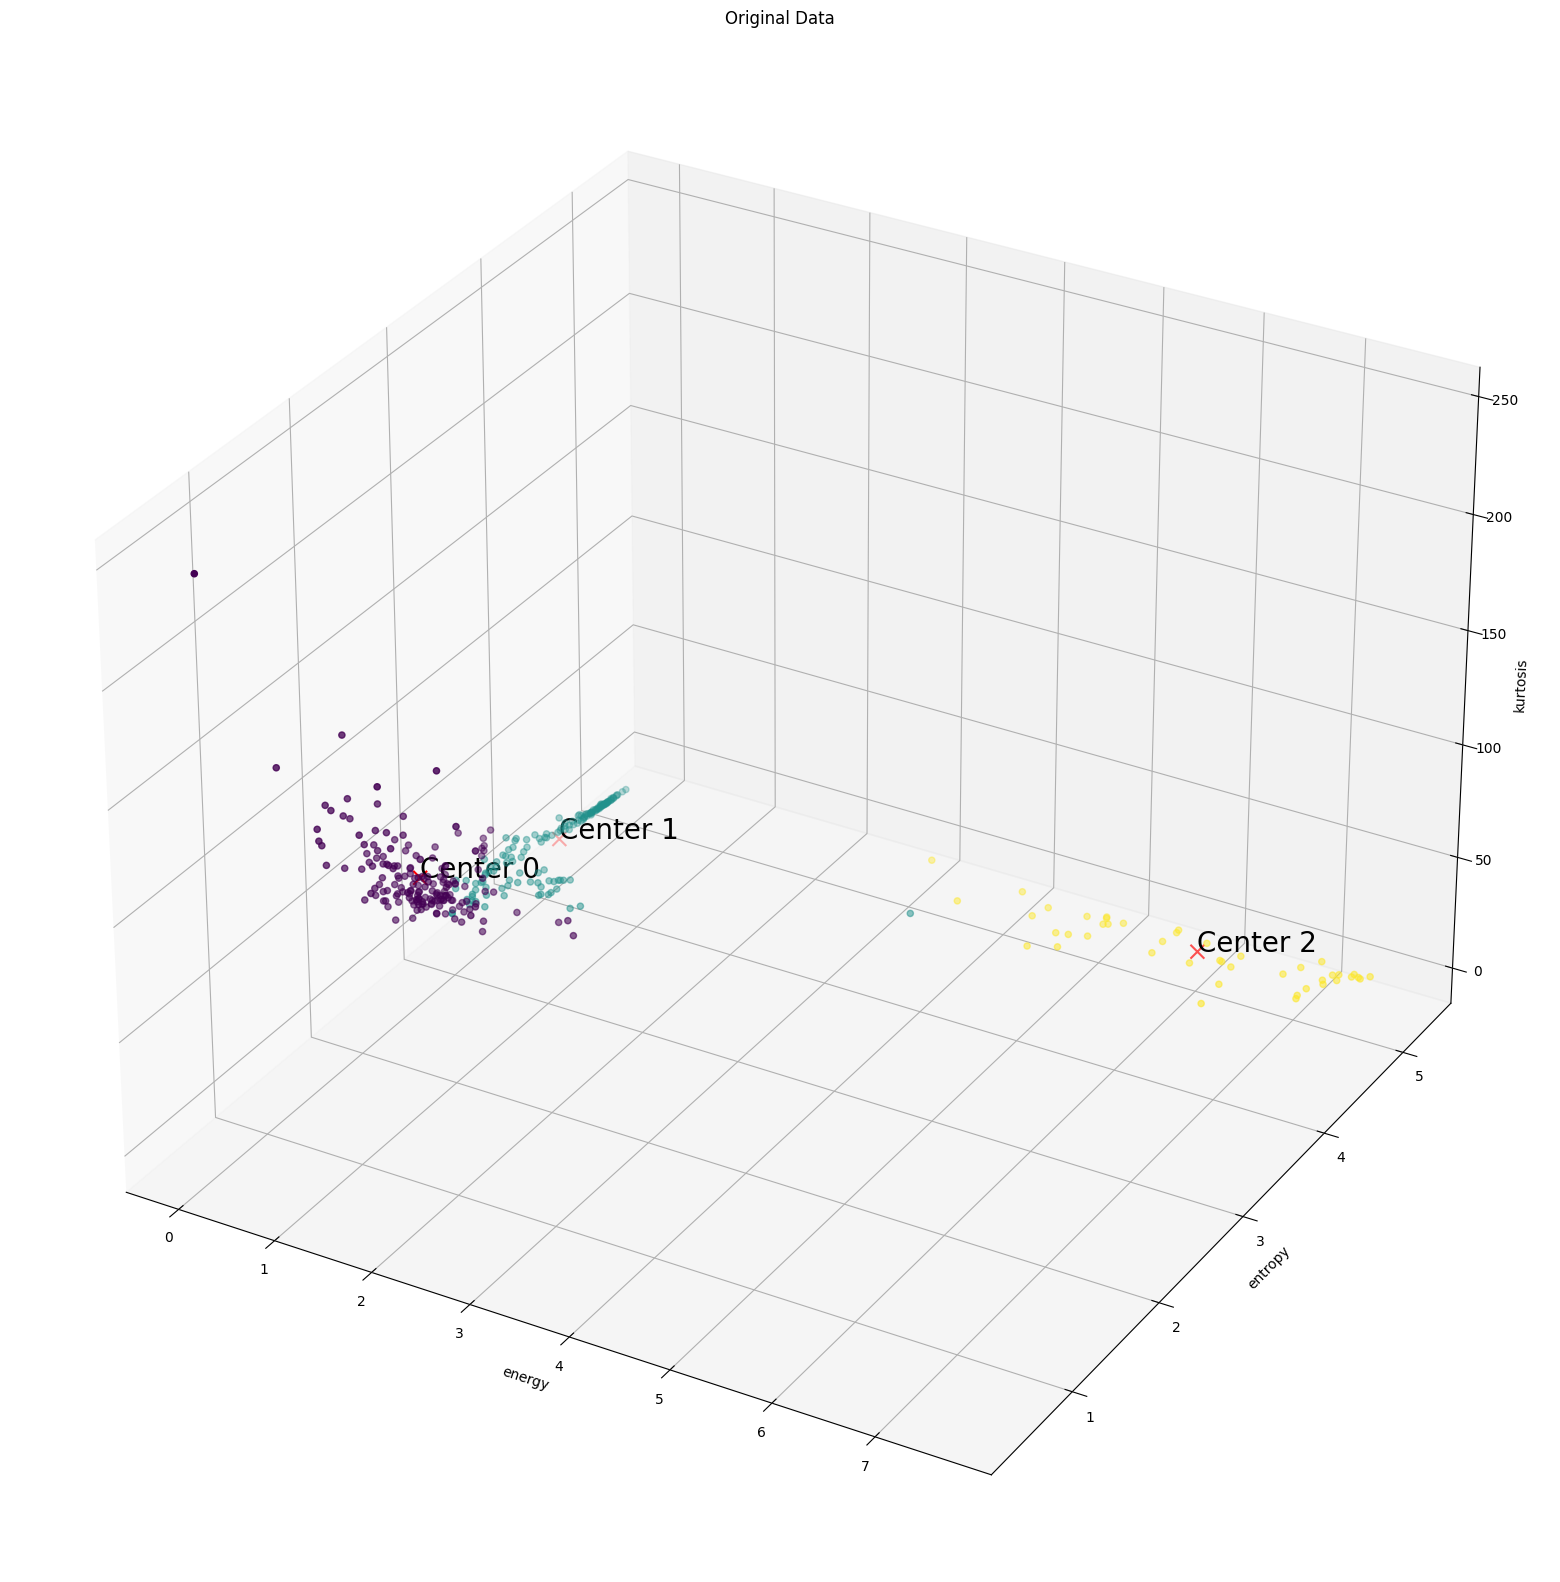

In [6]:
fig = plt.figure(figsize=(20, 20))
ax = fig.add_subplot(111, projection="3d")

title = "Original Data"

data_scatter = data_train.values.tolist()
centers_scatter = centers
color_map_labels = labels

# Plot data points
data_plot = ax.scatter(
    [point[0] for point in data_scatter],
    [point[1] for point in data_scatter],
    [point[2] for point in data_scatter],
    c=color_map_labels
)

# Plot cluster centers after data points
center_plot = ax.scatter(
    centers_scatter[:, 0],
    centers_scatter[:, 1],
    centers_scatter[:, 2],
    c="red",
    marker="x",
    s=100,
)

# Annotate cluster centers with their positions
for i, center in enumerate(centers_scatter):
    ax.text(center[0], center[1], center[2], f'Center {i}', color='black', fontsize=20)

ax.set_xlabel(data_train.columns[0])
ax.set_ylabel(data_train.columns[1])
ax.set_zlabel(data_train.columns[2])
ax.set_title(title)

plt.show()

### Classifying new data points

dynamics is inconsistent
clustering works better with fewer levels
need better standardisation of data

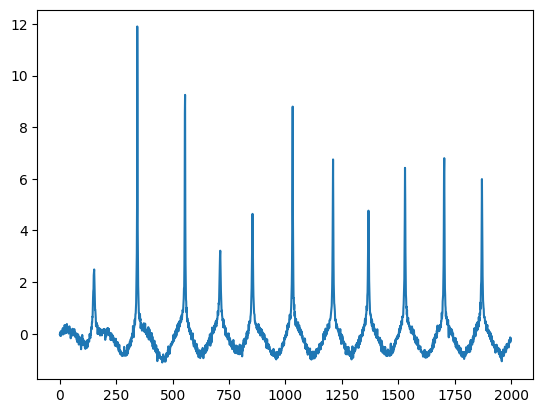

In [7]:
frequency = 3E5
pac = -1E5

min_energy = 0  # Only nodes with energy at least min_energy * total_energy will be considered

data = train.generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure)
data = (data - np.mean(data)) / np.std(data)
data = data[::step]
data += np.random.normal(0, 0.1, len(data))

new_wpt_df, new_tr_ob = train.generate_training_data(
    data, 
    levels,
    wavelet, 
    mode,
    min_energy=min_energy,
    include_tr_ob=True
)

new_wpt_df.head()

plt.plot(data)
plt.show()

In [8]:
# New testing data from signal
new_entry = new_wpt_df[classifying_metrics]

# Standardize the new entry using the same scaler
new_entry_normalized = scaler.transform(new_entry)

# Predict membership using the cluster centers and membership matrix
new_u, *_ = fuzz.cluster.cmeans_predict(
    new_entry_normalized.T,
    cntr,
    m=m,
    error=error,
    maxiter=100,
)

new_membership_matrix = new_u.T
# Convert membership to hard cluster assignment
new_labels = np.argmax(new_u, axis=0)

# Display the predicted results
print("Predicted hard cluster assignment:", new_labels)

membership_results = pd.DataFrame()
for i, membership in enumerate(new_membership_matrix):
    membership_results.loc[i, "hard assignment"] = new_labels[i]
    for j in range(no_clusters):
        membership_results.loc[i, f"membership {j}"] = membership[j]

membership_results

Predicted hard cluster assignment: [2 1 1 0 1 0 1 1]


,hard assignment,membership 0,membership 1,membership 2
0,2.0,0.006238,0.019153,0.974608
1,1.0,0.001278,0.997790,0.000932
2,1.0,0.483192,0.511033,0.005775
3,0.0,0.999510,0.000454,0.000036
4,1.0,0.247132,0.748236,0.004632
5,0.0,0.988240,0.010885,0.000875
6,1.0,0.000387,0.999376,0.000237
7,1.0,0.002139,0.996314,0.001546


### Reconstructing by cluster

Reconstructed nodes by group:


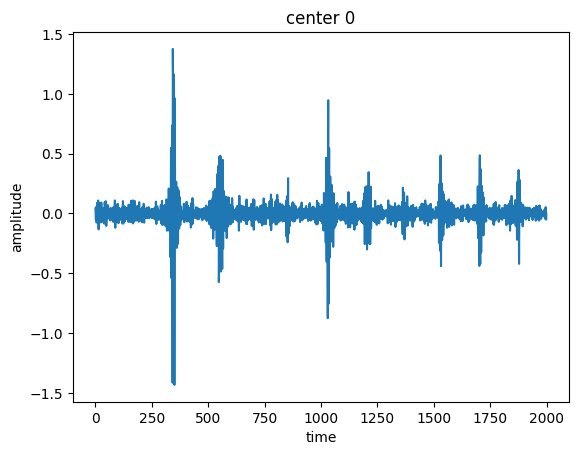

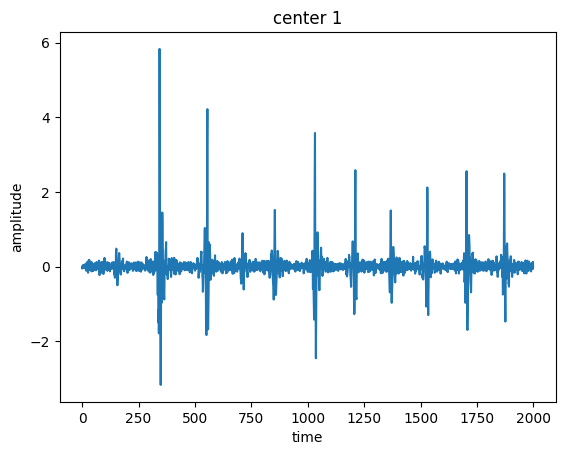

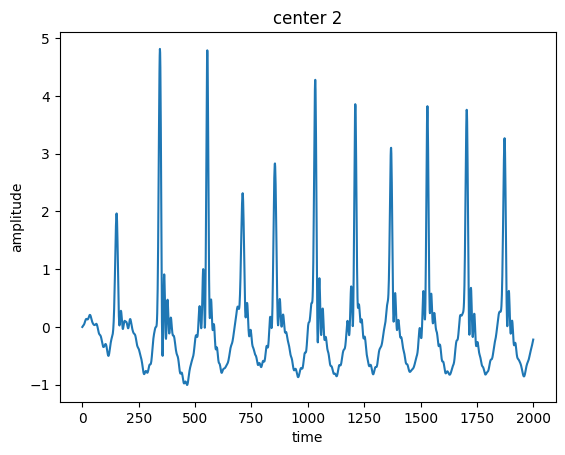

In [9]:
# List reconstructions by group
reconstructions = [np.zeros(len(data)) for _ in range(no_clusters)]

# Sum all reconstructions belonging to the same group
plot.plot_reconstructions_by_group(new_tr_ob, new_labels, no_clusters, order="freq")

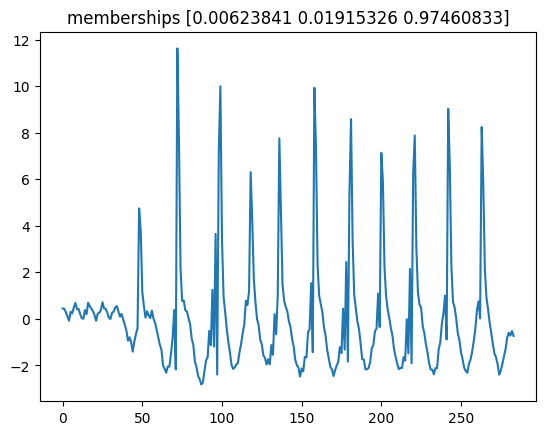

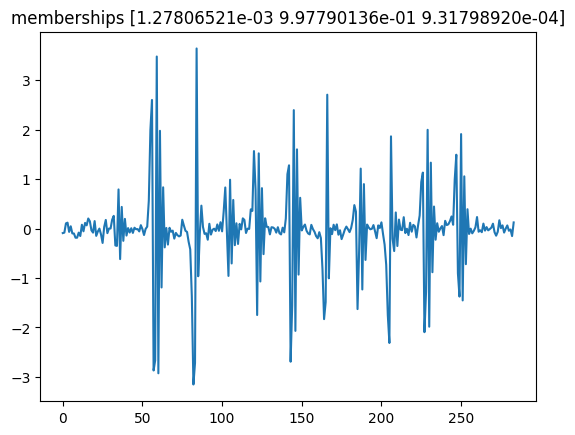

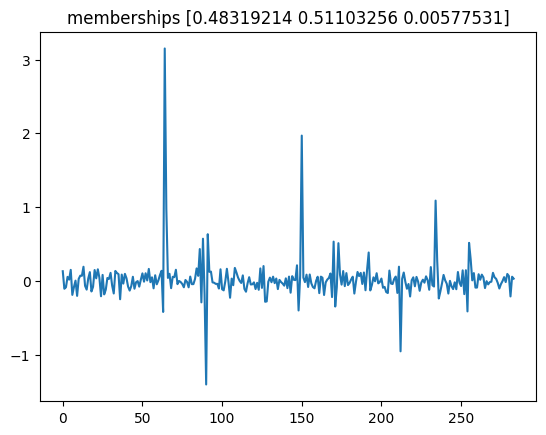

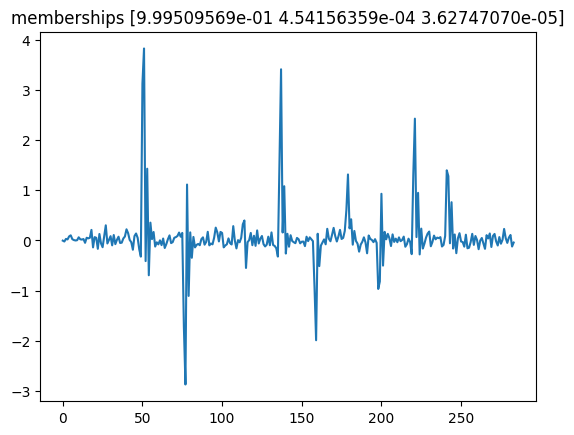

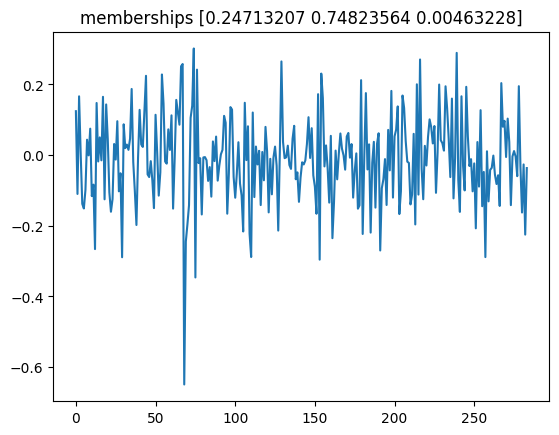

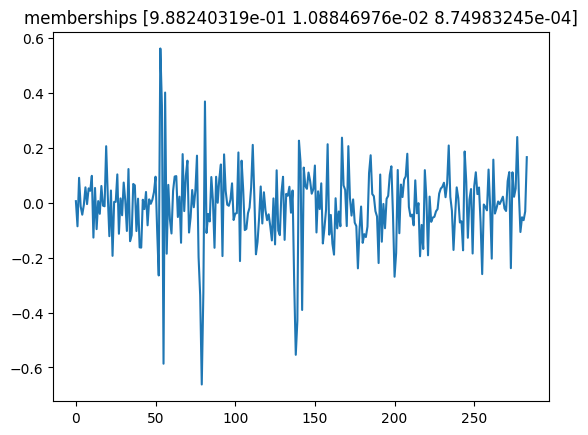

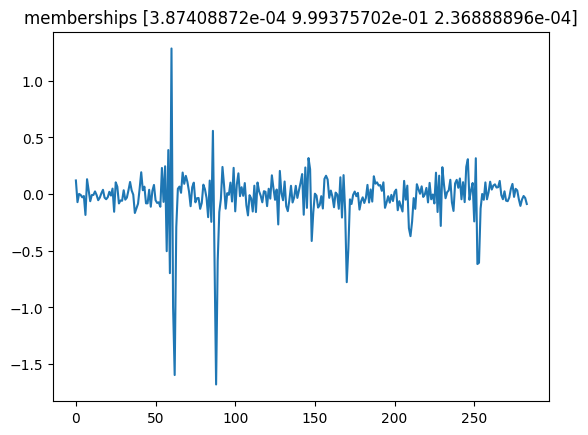

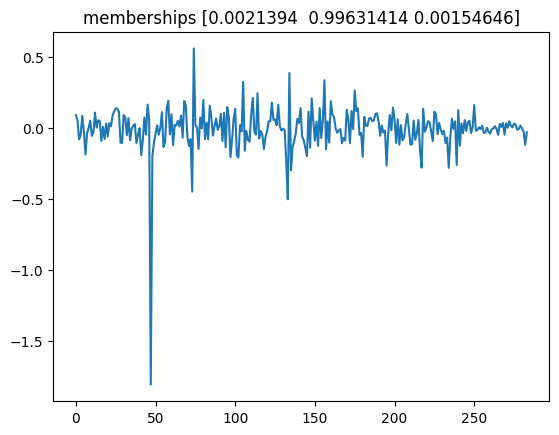

In [10]:
# Plot each node 
i = 0
total_energy = sum(node.energy for node in new_tr_ob.get_level(level=levels))
for node in new_tr_ob.get_level():
    if node.energy / total_energy > min_energy:
        plt.plot(node.data)
        plt.title(f"memberships {new_membership_matrix[i]}")
        plt.show()
        i += 1